# 02 - Baselines and first XGBoost model

**Goal:** a simple, honest first model, with a baseline to beat and a short error analysis. No hyper-parameter search (on purpose).

**Design (from the EDA)**
- `refund` is a **deterministic rule** (amount > 0), applied before the model. XGBoost is trained on non-refund rows only (11 classes).
- Text: character 2-4-grams (presence, not weights) of the normalized merchant name, vocabulary capped at 2,000 n-grams.
- Other features: amount (abs), entry method (rare values grouped), `digitalization_type`, recurring flag, empty-name flag, hour, day of week, day of month.
- Dropped: ids, names, currency, fees, card type, `status`, month, `card_name` (to be cleaned and re-added later).
- `major_category` is **derived** from the predicted minor class (strict hierarchy; refund -> `none`).
- All feature code lives in `src/txlabel/` (`preprocessing.py`, `model.py`), so training, this notebook and the future API share it.

**Evaluation**: stratified random 80/20 split after removing the 120 exact `ref_id` duplicates. Primary metric: macro-F1; accuracy is read against the
~96% ceiling found in the EDA. The split strategy is a first, simple choice and is revisited later (grouped by merchant, temporal).

## 1. Data, deduplication and split

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

from txlabel.model import TransactionClassifier
from txlabel.preprocessing import MINOR_TO_MAJOR, REFUND, build_features, is_refund

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
SEED = 42

raw = pd.read_csv(
    "../data/raw/transaction-dataset-1.csv",
    keep_default_na=False,
    dtype={"transaction_id": str, "member_id": str, "ref_id": str, "merchant_id": str},
)
print("raw rows:", len(raw))
df = raw.drop_duplicates(subset="ref_id", keep="first").copy()
print("after dropping exact ref_id duplicates:", len(df), f"({len(raw) - len(df)} removed)")

raw rows: 8121
after dropping exact ref_id duplicates: 8001 (120 removed)


In [2]:
train, test = train_test_split(df, test_size=0.2, stratify=df["minor_category"], random_state=SEED)
print(f"train: {len(train)} | test: {len(test)}")
dist = pd.concat([train["minor_category"].value_counts(normalize=True).rename("train"),
                  test["minor_category"].value_counts(normalize=True).rename("test")], axis=1).round(3)
dist

train: 6400 | test: 1601


,train,test
minor_category,,
supermarkets,0.293,0.292
multimedia,0.192,0.192
restaurants,0.158,0.157
transport_means,0.106,0.106
betting,0.062,0.062
tolls_gas_stations,0.054,0.054
atm,0.044,0.044
others_shopping,0.024,0.024
travel_means,0.022,0.022


## 2. Evaluation helper
Every model is evaluated end to end on **all** test rows (refunds included), on both targets.

In [3]:
results = []

def evaluate(name, y_true, y_pred):
    y_true_major = y_true.map(MINOR_TO_MAJOR)
    y_pred_major = pd.Series(y_pred, index=y_true.index).map(MINOR_TO_MAJOR)
    row = {
        "model": name,
        "minor_accuracy": accuracy_score(y_true, y_pred),
        "minor_macro_f1": f1_score(y_true, y_pred, average="macro"),
        "minor_weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "major_accuracy": accuracy_score(y_true_major, y_pred_major),
        "major_macro_f1": f1_score(y_true_major, y_pred_major, average="macro"),
    }
    results.append(row)
    return row

y_test = test["minor_category"]

## 3. Baselines
1. **Majority class**: always predict the most frequent class (the floor).
2. **Rules + merchant lookup**: amount > 0 -> refund; otherwise the majority class of the normalized merchant name seen in the training set
   (fallback: overall majority for unseen merchants). This tells how much of the problem is plain lookup.

In [4]:
train_nr = train[~is_refund(train)]
global_majority = train_nr["minor_category"].value_counts().index[0]
print("global majority class (non-refund):", global_majority)

# baseline 1
evaluate("1. majority class", y_test, pd.Series(global_majority, index=test.index))

# baseline 2
train_names = build_features(train_nr)["name_norm"]
name_majority = train_nr["minor_category"].groupby(train_names).agg(lambda s: s.value_counts().index[0])

def rules_lookup(raw_df):
    names = build_features(raw_df)["name_norm"]
    pred = names.map(name_majority).fillna(global_majority)
    pred[is_refund(raw_df)] = REFUND
    return pred

pred_rules = rules_lookup(test)
evaluate("2. refund rule + merchant lookup", y_test, pred_rules)
print("test rows with a merchant name unseen in train:", f"{(~build_features(test)['name_norm'].isin(name_majority.index)).mean():.1%}")
pd.DataFrame(results).set_index("model").round(4)

global majority class (non-refund): supermarkets


test rows with a merchant name unseen in train: 5.7%


,minor_accuracy,minor_macro_f1,minor_weighted_f1,major_accuracy,major_macro_f1
model,,,,,
1. majority class,0.2923,0.0377,0.1322,0.2923,0.0503
2. refund rule + merchant lookup,0.9094,0.8855,0.9075,0.9200,0.8926


## 4. XGBoost (refund rule + XGBoost on the rest)
Fixed hyper-parameters (300 trees, depth 6, learning rate 0.1, subsample 0.8, colsample 0.5), no tuning, no class weights.

In [5]:
t0 = time.time()
clf = TransactionClassifier(seed=SEED).fit(train, train["minor_category"])
print(f"fit in {time.time() - t0:.1f}s")

proba = clf.predict_proba(test)
pred_xgb = proba.idxmax(axis=1)
evaluate("3. refund rule + XGBoost", y_test, pred_xgb)
comparison = pd.DataFrame(results).set_index("model").round(4)
comparison

fit in 4.8s


,minor_accuracy,minor_macro_f1,minor_weighted_f1,major_accuracy,major_macro_f1
model,,,,,
1. majority class,0.2923,0.0377,0.1322,0.2923,0.0503
2. refund rule + merchant lookup,0.9094,0.8855,0.9075,0.9200,0.8926
3. refund rule + XGBoost,0.9338,0.9177,0.9322,0.9457,0.9210


### 4.1 Per-class results

In [6]:
print(classification_report(y_test, pred_xgb, digits=3))

                    precision    recall  f1-score   support

               atm      0.972     1.000     0.986        70
           betting      0.924     0.850     0.885       100
       hairdresser      1.000     0.875     0.933        24
        multimedia      0.938     0.974     0.955       308
   others_shopping      0.917     0.564     0.698        39
        pharmacies      0.960     0.923     0.941        26
            refund      1.000     1.000     1.000        24
       restaurants      0.911     0.897     0.904       252
      supermarkets      0.929     0.985     0.956       468
tolls_gas_stations      0.975     0.907     0.940        86
   transport_means      0.922     0.911     0.917       169
      travel_means      0.938     0.857     0.896        35

          accuracy                          0.934      1601
         macro avg      0.949     0.895     0.918      1601
      weighted avg      0.934     0.934     0.932      1601



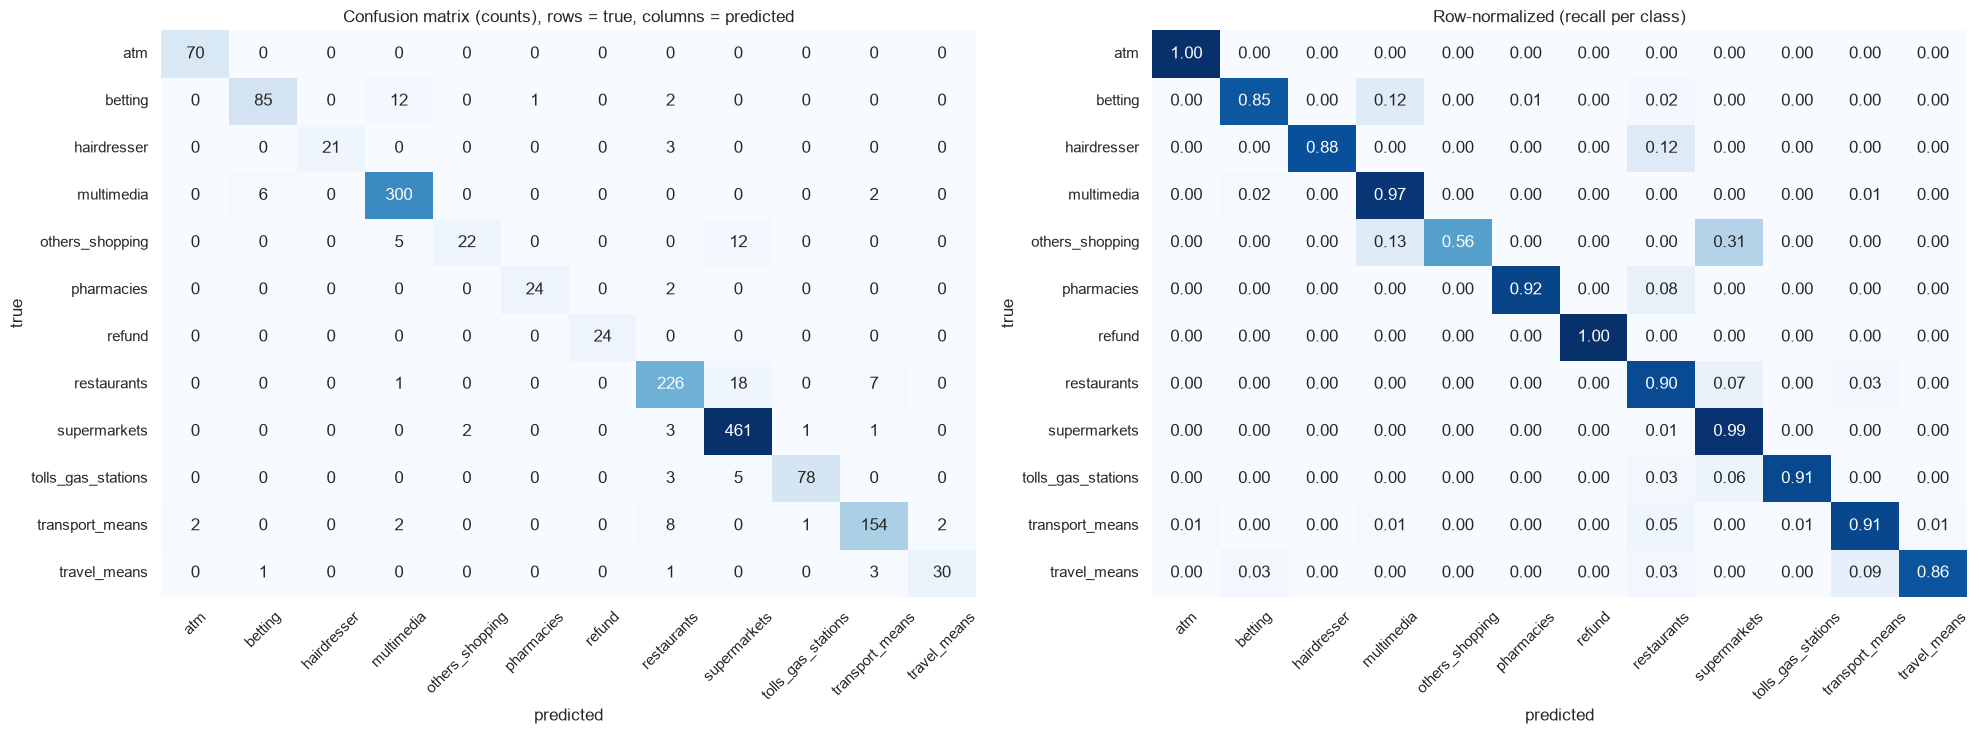

In [7]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, pred_xgb, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Confusion matrix (counts), rows = true, columns = predicted")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=labels, yticklabels=labels, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Row-normalized (recall per class)")
for ax in axes:
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [8]:
# accuracy on non-refund rows only, compared with the ceiling estimated in the EDA (3.9% of non-refund rows contradict their merchant's majority label)
nr = ~is_refund(test)
for name, pred in [("merchant lookup", pred_rules), ("XGBoost", pred_xgb)]:
    print(f"{name:16s}: accuracy on non-refund test rows = {accuracy_score(y_test[nr], pred[nr]):.4f}")
print("EDA ceiling (1 - 3.9% label disagreement): ~0.961")

merchant lookup : accuracy on non-refund test rows = 0.9081
XGBoost         : accuracy on non-refund test rows = 0.9328
EDA ceiling (1 - 3.9% label disagreement): ~0.961


In [9]:
# major-level report (derived from the predicted minor class)
y_major = y_test.map(MINOR_TO_MAJOR)
print(classification_report(y_major, pred_xgb.map(MINOR_TO_MAJOR), digits=3))

                        precision    recall  f1-score   support

         entertainment      0.978     0.988     0.983       408
               finance      0.972     1.000     0.986        70
             groceries      0.929     0.985     0.956       468
                  none      1.000     1.000     1.000        24
restaurants_bars_cafes      0.911     0.897     0.904       252
             self_care      0.978     0.900     0.938        50
              shopping      0.917     0.564     0.698        39
        transportation      0.943     0.914     0.928       255
                travel      0.938     0.857     0.896        35

              accuracy                          0.946      1601
             macro avg      0.952     0.901     0.921      1601
          weighted avg      0.946     0.946     0.944      1601



## 5. Brief error analysis
Questions: where does the model fail, and are the failures *model* errors or *label* errors?

For each non-refund test row we compare its label with the **majority label of its merchant in the training set**:
- *unseen merchant*: the name never appears in train,
- *label deviates from merchant majority*: probably label noise or a genuinely unusual transaction (e.g. a restaurant inside a supermarket),
- *label equals merchant majority*: if the model is wrong here, it is a real model error.

In [10]:
test_nr = test[nr].copy()
test_nr["name"] = build_features(test_nr)["name_norm"]
test_nr["pred"] = pred_xgb[nr]
test_nr["conf"] = proba.loc[nr].max(axis=1)
test_nr["error"] = test_nr["pred"] != test_nr["minor_category"]
test_nr["train_majority"] = test_nr["name"].map(name_majority)
test_nr["cause"] = np.select(
    [test_nr["train_majority"].isna(), test_nr["train_majority"] != test_nr["minor_category"]],
    ["unseen merchant", "label deviates from merchant majority"],
    default="label equals merchant majority",
)

summary = test_nr.groupby("cause").agg(rows=("error", "size"), errors=("error", "sum"))
summary["error_rate"] = (summary["errors"] / summary["rows"]).round(3)
summary["share_of_all_errors"] = (summary["errors"] / summary["errors"].sum()).round(3)
print(f"non-refund test rows: {len(test_nr)} | errors: {int(test_nr['error'].sum())}")
summary

non-refund test rows: 1577 | errors: 106


,rows,errors,error_rate,share_of_all_errors
cause,,,,
label deviates from merchant majority,69,66,0.957,0.623
label equals merchant majority,1417,14,0.010,0.132
unseen merchant,91,26,0.286,0.245


In [11]:
# most frequent confusions (true -> predicted)
conf = (test_nr[test_nr["error"]].groupby(["minor_category", "pred"]).size()
        .sort_values(ascending=False).head(12).rename("n").reset_index())
conf

,minor_category,pred,n
0,restaurants,supermarkets,18
1,betting,multimedia,12
2,others_shopping,supermarkets,12
3,transport_means,restaurants,8
4,restaurants,transport_means,7
5,multimedia,betting,6
6,tolls_gas_stations,supermarkets,5
7,others_shopping,multimedia,5
8,hairdresser,restaurants,3
9,tolls_gas_stations,restaurants,3


In [12]:
# errors by merchant frequency in train (how well do we do on rare vs frequent merchants?)
freq_train = train_nr.groupby(train_names).size()
test_nr["merchant_train_count"] = test_nr["name"].map(freq_train).fillna(0)
bins = pd.cut(test_nr["merchant_train_count"], [-1, 0, 5, 20, 100, 10_000], labels=["unseen", "1-5", "6-20", "21-100", ">100"])
display(test_nr.groupby(bins, observed=True).agg(rows=("error", "size"), error_rate=("error", "mean")).round(3))

,rows,error_rate
merchant_train_count,,
unseen,91,0.286
1-5,250,0.068
6-20,158,0.057
21-100,555,0.041
>100,523,0.059


In [13]:
# the most confident wrong predictions: are these label noise?
cols = ["name", "abs_amount", "minor_category", "pred", "conf", "cause"]
view = test_nr.assign(abs_amount=test_nr["amount_value"].abs())
view[view["error"]].sort_values("conf", ascending=False).head(15)[cols].round(3)

,name,abs_amount,minor_category,pred,conf,cause
1302,betclic,150.00,multimedia,betting,0.999,label deviates from merchant majority
7641,apple com bill,5.02,others_shopping,multimedia,0.999,label deviates from merchant majority
4461,apple com bill,5.24,betting,multimedia,0.999,label deviates from merchant majority
2043,retrait dab,310.00,transport_means,atm,0.999,label deviates from merchant majority
1189,google one,10.34,betting,multimedia,0.998,label deviates from merchant majority
7633,apple com bill,7.99,others_shopping,multimedia,0.998,label deviates from merchant majority
5696,apple com bill,6.99,betting,multimedia,0.998,label deviates from merchant majority
6297,betclic,40.92,multimedia,betting,0.998,label deviates from merchant majority
1861,apple com bill,9.93,betting,multimedia,0.997,label deviates from merchant majority
7554,apple com bill,10.41,others_shopping,multimedia,0.997,label deviates from merchant majority


In [14]:
# recall per class split by cause: where do the minority classes lose?
rec = test_nr.groupby("minor_category").agg(rows=("error", "size"), errors=("error", "sum"),
                                            deviating_labels=("cause", lambda s: (s == "label deviates from merchant majority").sum()))
rec["errors_not_explained_by_deviating_label"] = (
    test_nr[test_nr["error"] & (test_nr["cause"] != "label deviates from merchant majority")].groupby("minor_category").size()
    .reindex(rec.index).fillna(0).astype(int)
)
rec

,rows,errors,deviating_labels,errors_not_explained_by_deviating_label
minor_category,,,,
atm,70,0,0,0
betting,100,15,10,5
hairdresser,24,3,0,3
multimedia,308,8,6,2
others_shopping,39,17,16,1
pharmacies,26,2,0,2
restaurants,252,26,18,9
supermarkets,468,7,6,3
tolls_gas_stations,86,8,1,7


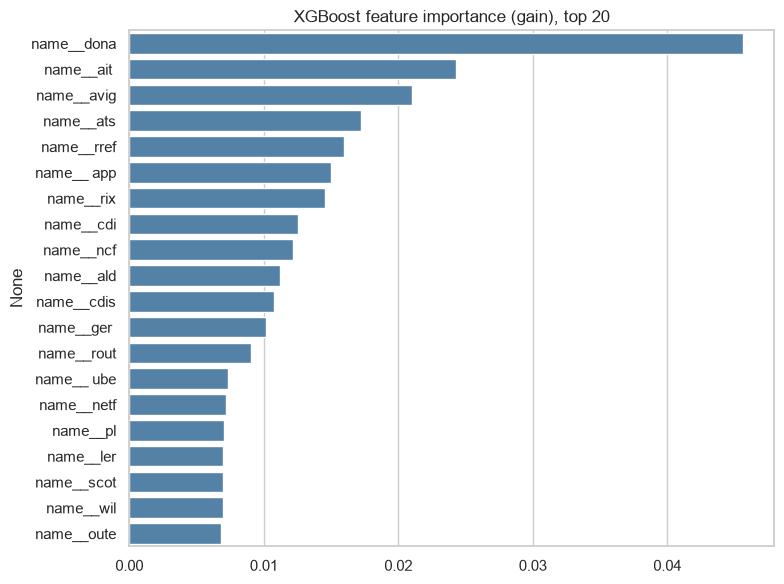

In [15]:
imp = clf.feature_importances().head(20)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, ax=ax, color="steelblue")
ax.set_title("XGBoost feature importance (gain), top 20")
plt.tight_layout(); plt.show()

## 6. Conclusions and next ideas

**Results** (test = 1,601 rows, stratified random split, after removing the 120 duplicates)

| model | minor accuracy | minor macro-F1 | major accuracy | major macro-F1 |
|---|---|---|---|---|
| majority class | 0.292 | 0.038 | 0.292 | 0.050 |
| refund rule + merchant lookup | 0.909 | 0.886 | 0.920 | 0.893 |
| **refund rule + XGBoost** | **0.934** | **0.918** | **0.946** | **0.921** |

- XGBoost beats the lookup baseline by about +2.4 points of accuracy and +3.2 points of macro-F1. Refund is perfect (rule). `atm` has recall 1.0.
- The weakest class is `others_shopping` (recall 0.56, F1 0.70).

**Error analysis** (non-refund test rows: 1,577 rows, 106 errors)

| cause | rows | errors | error rate | share of errors |
|---|---|---|---|---|
| label deviates from the merchant's majority label | 69 | 66 | 96% | 62% |
| unseen merchant | 91 | 26 | 29% | 25% |
| label equals the merchant's majority (real model error) | 1,417 | 14 | 1.0% | 13% |

- **Most errors are not model errors.** On rows whose label contradicts their merchant's usual label (probable label noise, or genuinely unusual transactions), the model sides with the merchant 96% of the time and is "wrong".
  If those rows are unpredictable, the practical ceiling on this split is about **95.6%** of non-refund rows (current: 93.3%), consistent with the ~96% ceiling from the EDA.
- **The real room for improvement is unseen merchants** (error rate 29% vs 4 to 7% for merchants seen in training). A random split has only 5.7% unseen merchants, so real-world performance on new merchants may be worse.
- Confusions match the EDA notes: restaurants -> supermarkets (18), betting <-> multimedia (12 + 6), others_shopping -> supermarkets (12), restaurants <-> transport_means (8 + 7; delivery, in-store cafeterias).
  The most confident errors are almost all of this type (e.g. `apple.com/bill` labeled betting or others_shopping), so **confidence does not flag them**.
- `others_shopping` is hard because 16 of its 39 test rows carry a label that contradicts the merchant's usual label (supermarket names, `apple.com/bill`): the class is largely defined by context the features do not contain.

**What the model uses**
- About 99% of the XGBoost gain is on merchant-name n-grams. A quick ablation run outside this notebook (single split, non-refund rows) gave accuracy / macro-F1 of 0.9353 / 0.9172 for the **name alone**,
  vs 0.9328 / 0.9102 for all features: amount, time, entry method and digitalization add **nothing measurable** here (differences are within noise, about 4 rows).
  The hour-of-day patterns seen in the EDA come from *which merchants* are visited at which times, not from time itself.

**Caveats**
- One split of 1,601 rows; small classes have 24 to 39 test rows, so per-class numbers and differences below about 1 point are not reliable. No confidence intervals yet.
- "Deviating label" is defined against the training majority, which is itself noisy for rare merchants. It is a diagnostic, not ground truth.
- Hyper-parameters are not tuned and class weights are not used (on purpose, to keep this a first iteration).

**Ideas, not done (for the README)**
1. Unseen merchants (the main lever): fuzzy / embedding features, nearest-known-merchant features, handling of truncated names; check whether the Levenshtein cluster adds anything over the n-grams.
2. Stacking: logistic regression on the n-grams, with its out-of-fold probabilities fed to XGBoost.
3. Evaluation: merchant-grouped split and cross-validation with confidence intervals; temporal split as a stress test.
4. Small classes: class weights or per-class thresholds; calibration and an "unsure" fallback for low-confidence predictions.
5. Re-add a cleaned `card_name` (merge FR / EN duplicates) and test it; make the ablation above a proper notebook cell.
6. Investigate the deviating labels with domain knowledge (cafeterias inside supermarkets, delivery apps) to decide what is noise and what is a real second behaviour.
7. Re-check the choice of keeping structured features at all, since they add no measurable value (simpler model, less to validate at serving time).